In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(seed=42)

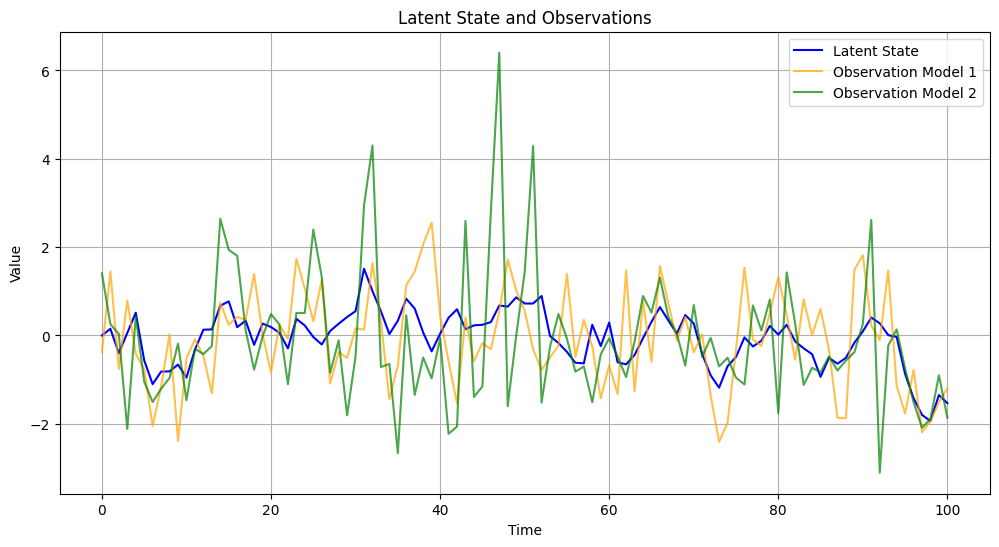

In [3]:
sigma = 1

def latent_state(T, rho, tau):
    x = np.zeros(T + 1)
    for t in range(1, T + 1):
        x[t] = rho * x[t - 1] + tau * rng.standard_normal()
    return x

x = latent_state(T=100, rho=0.8, tau=0.5)

obs_model1 = x + sigma * rng.standard_normal(size=x.shape)
obs_model2 = x + sigma * np.exp(x) * rng.standard_normal(size=x.shape)

plt.figure(figsize=(12, 6))
plt.plot(x, label='Latent State', color='blue')
plt.plot(obs_model1, label='Observation Model 1', color='orange', alpha=0.7)
plt.plot(obs_model2, label='Observation Model 2', color='green', alpha=0.7)
plt.title('Latent State and Observations')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.grid()
plt.show()

In [4]:
sigma = np.linspace(0.01, 2, 200)

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# If not defined yet:
# rng = np.random.default_rng(123)

# --------------------------------------------------
# Kalman filter log-likelihood for Model 1
# X_n = A X_{n-1} + B V_n
# Y_n = C X_n + D W_n
# --------------------------------------------------
def KF(y, D, A=0.8, B=0.5, C=1.0):
    # X0 ~ N(0,1)
    m, v = 0.0, 1.0
    loglik = 0.0
    T = len(y)

    # t = 0: use X0 directly, no state transition before observing y0
    M = C * m
    V = C**2 * v + D**2
    loglik += -0.5 * (np.log(2*np.pi) + np.log(V) + (y[0] - M)**2 / V)

    K = v * C / V
    m = m + K * (y[0] - M)
    v = v - K * C * v

    # t = 1,...,T-1
    for t in range(1, T):
        m_pred = A * m
        v_pred = A**2 * v + B**2

        M = C * m_pred
        V = C**2 * v_pred + D**2
        loglik += -0.5 * (np.log(2*np.pi) + np.log(V) + (y[t] - M)**2 / V)

        K = v_pred * C / V
        m = m_pred + K * (y[t] - M)
        v = v_pred - K * C * v_pred

    return loglik

def KF_state_estimates(y, D, A=0.8, B=0.5, C=1.0):
    m, v = 0.0, 1.0
    T = len(y)
    m_list = np.empty(T)
    v_list = np.empty(T)

    M = C * m
    V = C**2 * v + D**2

    K = v * C / V
    m = m + K * (y[0] - M)
    v = v - K * C * v

    m_list[0] = m
    v_list[0] = v

    for t in range(1, T):
        m_pred = A * m
        v_pred = A**2 * v + B**2

        M = C * m_pred
        V = C**2 * v_pred + D**2

        K = v_pred * C / V
        m = m_pred + K * (y[t] - M)
        v = v_pred - K * C * v_pred

        m_list[t] = m
        v_list[t] = v

    return m_list, v_list


# --------------------------------------------------
# Particle filter log-likelihood for Model 1
# X_n = A X_{n-1} + B V_n
# Y_n = X_n + sigma W_n
# --------------------------------------------------
def PF_model1(y, sigma, num=500, A=0.8, B=0.5):
    T = len(y)
    particles = np.empty((num, T))
    weights = np.empty((num, T))
    loglik = 0.0

    def log_weight(x, y_obs):
        var = sigma**2
        return -0.5 * (np.log(2 * np.pi * var) + (y_obs - x)**2 / var)

    # t = 0
    particles[:, 0] = rng.normal(0.0, 1.0, size=num)
    logw = log_weight(particles[:, 0], y[0])
    logw = np.where(np.isfinite(logw), logw, -1e300)

    m = np.max(logw)
    w = np.exp(logw - m)
    mean_w = np.mean(w)

    if (not np.isfinite(mean_w)) or (mean_w <= 0):
        weights[:, 0] = np.ones(num) / num
        loglik += -1e300
    else:
        loglik += m + np.log(mean_w)
        weights[:, 0] = w / np.sum(w)

    indices = rng.choice(num, size=num, replace=True, p=weights[:, 0])
    particles[:, 0] = particles[indices, 0]
    weights[:, 0] = np.ones(num) / num

    # t = 1,...,T-1
    for t in range(1, T):
        particles[:, t] = A * particles[:, t - 1] + rng.normal(0.0, B, size=num)

        logw = log_weight(particles[:, t], y[t])
        logw = np.where(np.isfinite(logw), logw, -1e300)

        m = np.max(logw)
        w = np.exp(logw - m)
        mean_w = np.mean(w)

        if (not np.isfinite(mean_w)) or (mean_w <= 0):
            weights[:, t] = np.ones(num) / num
            loglik += -1e300
        else:
            loglik += m + np.log(mean_w)
            weights[:, t] = w / np.sum(w)

        indices = rng.choice(num, size=num, replace=True, p=weights[:, t])
        particles[:, t] = particles[indices, t]
        weights[:, t] = np.ones(num) / num

    return loglik, particles, weights


# --------------------------------------------------
# Particle filter log-likelihood for Model 2
# X_n = A X_{n-1} + B V_n
# Y_n = X_n + sigma * exp(X_n / 2) * W_n
# --------------------------------------------------
def PF_model2(y, sigma, num=500, A=0.8, B=0.5):
    T = len(y)
    particles = np.empty((num, T))
    weights = np.empty((num, T))
    loglik = 0.0

    def log_weight(x, y_obs):
        var = sigma**2 * np.exp(x)
        var = np.maximum(var, 1e-300)
        return -0.5 * (np.log(2 * np.pi * var) + (y_obs - x)**2 / var)

    # t = 0
    particles[:, 0] = rng.normal(0.0, 1.0, size=num)
    logw = log_weight(particles[:, 0], y[0])
    logw = np.where(np.isfinite(logw), logw, -1e300)

    m = np.max(logw)
    w = np.exp(logw - m)
    mean_w = np.mean(w)

    if (not np.isfinite(mean_w)) or (mean_w <= 0):
        weights[:, 0] = np.ones(num) / num
        loglik += -1e300
    else:
        loglik += m + np.log(mean_w)
        weights[:, 0] = w / np.sum(w)

    indices = rng.choice(num, size=num, replace=True, p=weights[:, 0])
    particles[:, 0] = particles[indices, 0]
    weights[:, 0] = np.ones(num) / num

    # t = 1,...,T-1
    for t in range(1, T):
        particles[:, t] = A * particles[:, t - 1] + rng.normal(0.0, B, size=num)

        logw = log_weight(particles[:, t], y[t])
        logw = np.where(np.isfinite(logw), logw, -1e300)

        m = np.max(logw)
        w = np.exp(logw - m)
        mean_w = np.mean(w)

        if (not np.isfinite(mean_w)) or (mean_w <= 0):
            weights[:, t] = np.ones(num) / num
            loglik += -1e300
        else:
            loglik += m + np.log(mean_w)
            weights[:, t] = w / np.sum(w)

        indices = rng.choice(num, size=num, replace=True, p=weights[:, t])
        particles[:, t] = particles[indices, t]
        weights[:, t] = np.ones(num) / num

    return loglik, particles, weights

def plot_sim(y, sigma2_grid):
    loglik_kf = [KF(y, D=np.sqrt(s2)) for s2 in sigma2_grid]
    loglik_pf1 = [PF_model1(y, np.sqrt(s2))[0] for s2 in sigma2_grid]
    loglik_pf2 = [PF_model2(y, np.sqrt(s2))[0] for s2 in sigma2_grid]

    max_idx_kf = np.argmax(loglik_kf)
    max_idx_pf1 = np.argmax(loglik_pf1)
    max_idx_pf2 = np.argmax(loglik_pf2)

    plt.figure(figsize=(12, 6))
    plt.plot(sigma2_grid, loglik_kf, label=f'Kalman Filter (Model 1 exact), $\\sigma^2 = {sigma2_grid[max_idx_kf]:.2f}$', color='blue')
    plt.plot(sigma2_grid, loglik_pf1, label=f'Particle Filter (Model 1), $\\sigma^2 = {sigma2_grid[max_idx_pf1]:.2f}$', color='orange')
    plt.plot(sigma2_grid, loglik_pf2, label=f'Particle Filter (Model 2), $\\sigma^2 = {sigma2_grid[max_idx_pf2]:.2f}$', color='green')

    x_kf = sigma2_grid[np.argmax(loglik_kf)]
    x_pf1 = sigma2_grid[np.argmax(loglik_pf1)]
    x_pf2 = sigma2_grid[np.argmax(loglik_pf2)]

    plt.axvline(x_kf, color='blue', linestyle='--', alpha=0.7)
    plt.axvline(x_pf1, color='orange', linestyle='--', alpha=0.7)
    plt.axvline(x_pf2, color='green', linestyle='--', alpha=0.7)

    x_min = min(sigma2_grid)
    x_max = max(sigma2_grid)
    plt.xlim(x_min - 0.05, x_max + 0.05)

    base_ticks = list(np.arange(0, x_max + 0.001, 0.5))
    special_ticks = [round(x_kf, 2), round(x_pf1, 2), round(x_pf2, 2)]
    all_ticks = sorted(set([round(t, 2) for t in base_ticks + special_ticks]))

    labels = []
    for t in all_ticks:
        if t in special_ticks:
            labels.append(f'{t:.2f}')
        else:
            labels.append(f'{t:.1f}')

    plt.xticks(all_ticks, labels, rotation=30)

    plt.xlabel('Observation Noise Variance ($\\sigma^2$)')
    plt.ylabel('Log-Likelihood')
    plt.title('Log-Likelihood Curves')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

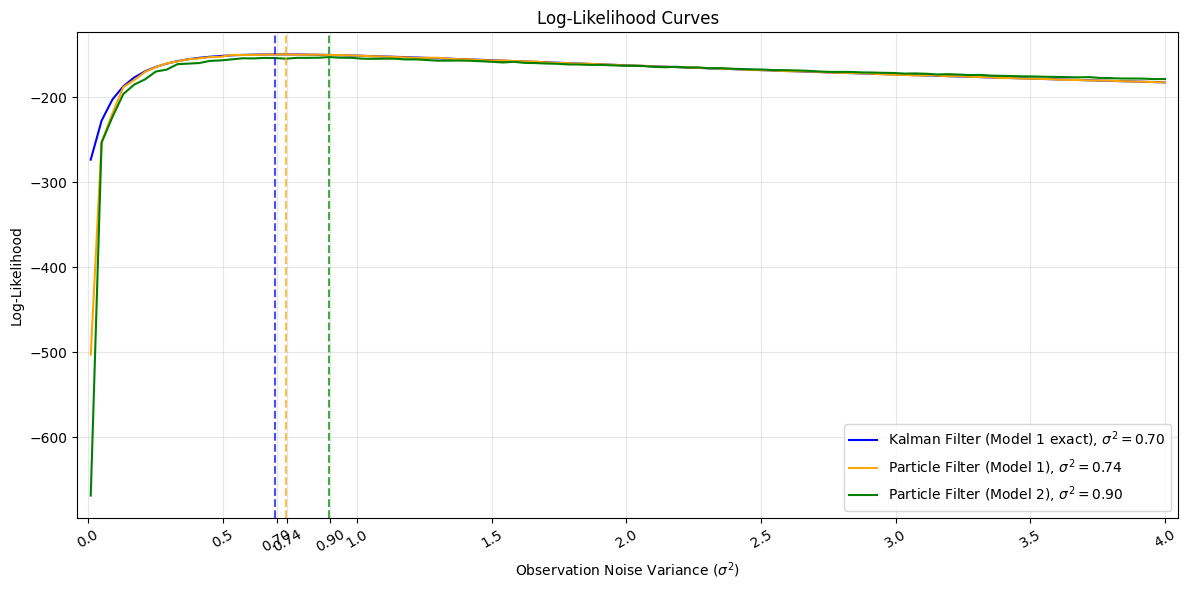

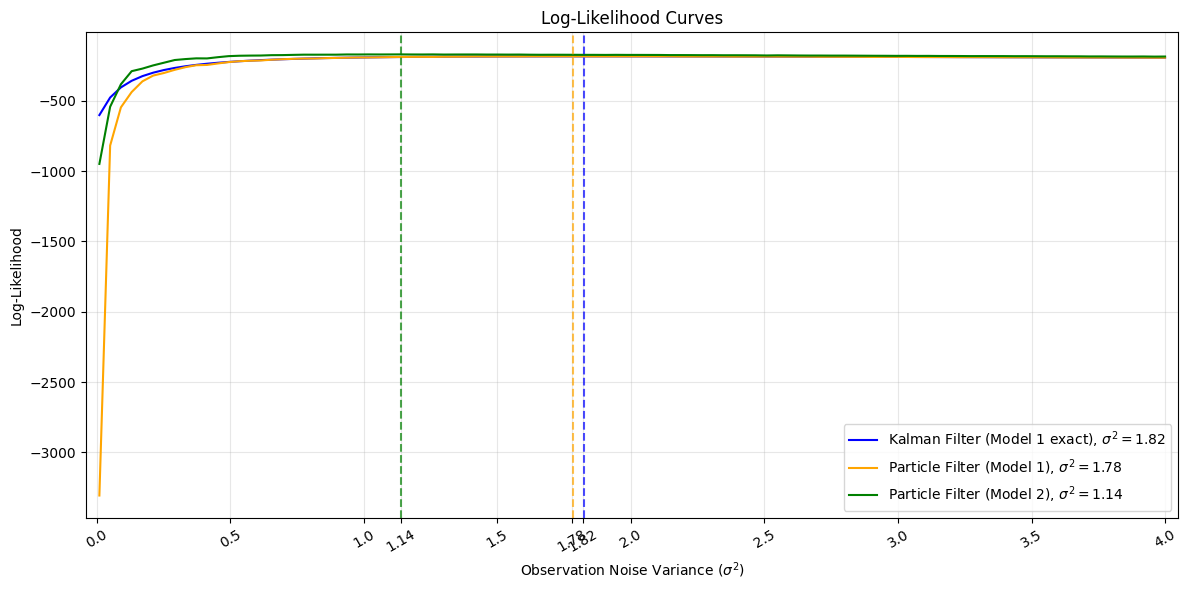

In [6]:
sigma2_grid = np.linspace(0.01, 4, 100)
plot_sim(obs_model1, sigma2_grid)
plot_sim(obs_model2, sigma2_grid)

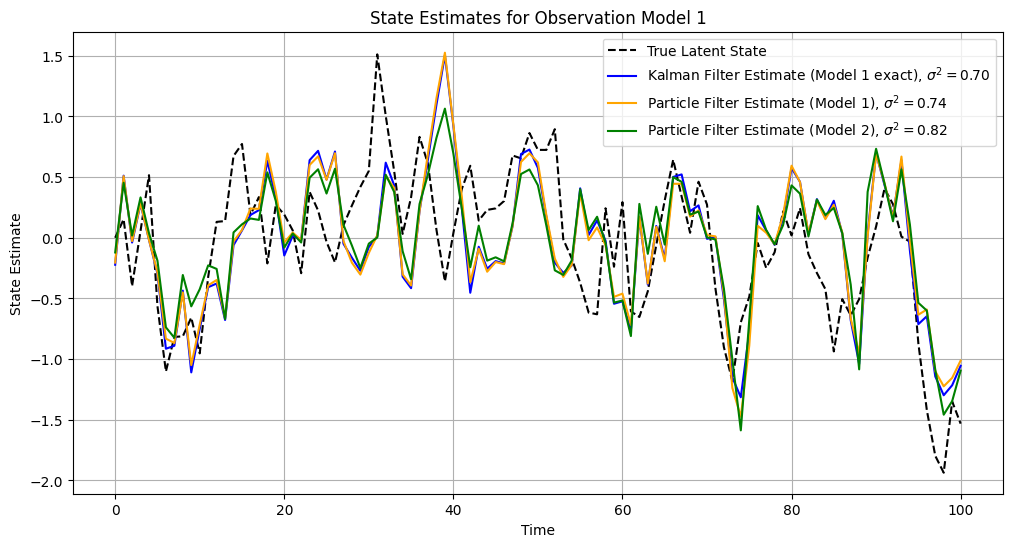

In [7]:
sigma2_list1 = [0.70, 0.74, 0.82]
m_kf1, _ = KF_state_estimates(obs_model1, D=np.sqrt(sigma2_list1[0]), A=0.8, B=0.5)
_, particles, weights = PF_model1(obs_model1, np.sqrt(sigma2_list1[1]), A=0.8, B=0.5)
m_pf1_ob1 = np.sum(particles * weights, axis=0)
_, particles, weights = PF_model2(obs_model1, np.sqrt(sigma2_list1[2]), A=0.8, B=0.5)
m_pf2_ob1 = np.sum(particles * weights, axis=0)
plt.figure(figsize=(12, 6))
plt.plot(x, label='True Latent State', color='black', linestyle='--')
plt.plot(m_kf1, label=f'Kalman Filter Estimate (Model 1 exact), $\\sigma^2 = {sigma2_list1[0]:.2f}$', color='blue')
plt.plot(m_pf1_ob1, label=f'Particle Filter Estimate (Model 1), $\\sigma^2 = {sigma2_list1[1]:.2f}$', color='orange')
plt.plot(m_pf2_ob1, label=f'Particle Filter Estimate (Model 2), $\\sigma^2 = {sigma2_list1[2]:.2f}$', color='green')
plt.title('State Estimates for Observation Model 1')
plt.xlabel('Time')
plt.ylabel('State Estimate')
plt.legend()
plt.grid()
plt.show()

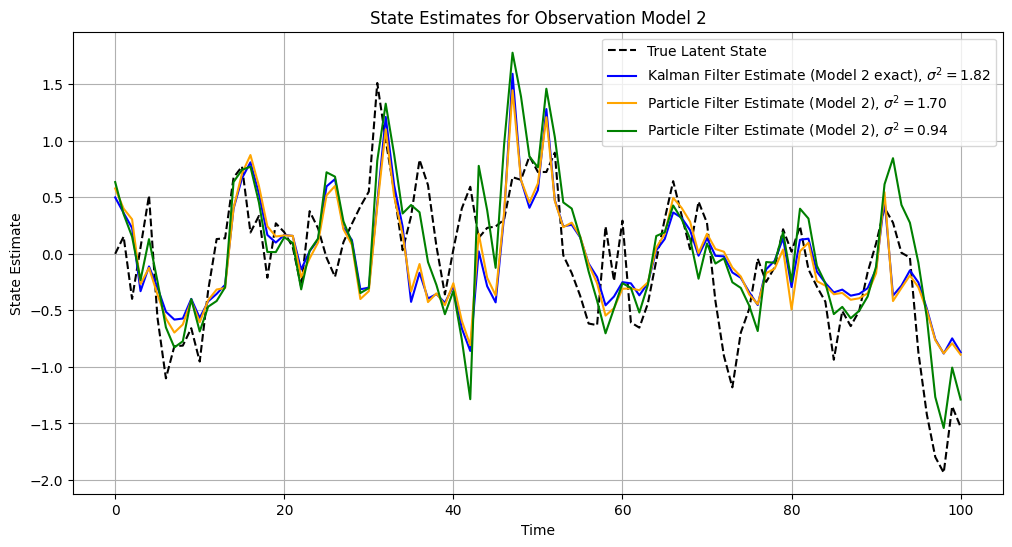

In [8]:
sigma2_list2 = [1.82, 1.70, 0.94]
m_kf2, _ = KF_state_estimates(obs_model2, D=np.sqrt(sigma2_list2[0]), A=0.8, B=0.5)
_, particles, weights = PF_model1(obs_model2, np.sqrt(sigma2_list2[1]), A=0.8, B=0.5)
m_pf1_ob2 = np.sum(particles * weights, axis=0)
_, particles, weights = PF_model2(obs_model2, np.sqrt(sigma2_list2[2]), A=0.8, B=0.5)
m_pf2_ob2 = np.sum(particles * weights, axis=0)
plt.figure(figsize=(12, 6))
plt.plot(x, label='True Latent State', color='black', linestyle='--')
plt.plot(m_kf2, label=f'Kalman Filter Estimate (Model 2 exact), $\\sigma^2 = {sigma2_list2[0]:.2f}$', color='blue')
plt.plot(m_pf1_ob2, label=f'Particle Filter Estimate (Model 2), $\\sigma^2 = {sigma2_list2[1]:.2f}$', color='orange')
plt.plot(m_pf2_ob2, label=f'Particle Filter Estimate (Model 2), $\\sigma^2 = {sigma2_list2[2]:.2f}$', color='green')
plt.title('State Estimates for Observation Model 2')
plt.xlabel('Time')
plt.ylabel('State Estimate')
plt.legend()
plt.grid()
plt.show()

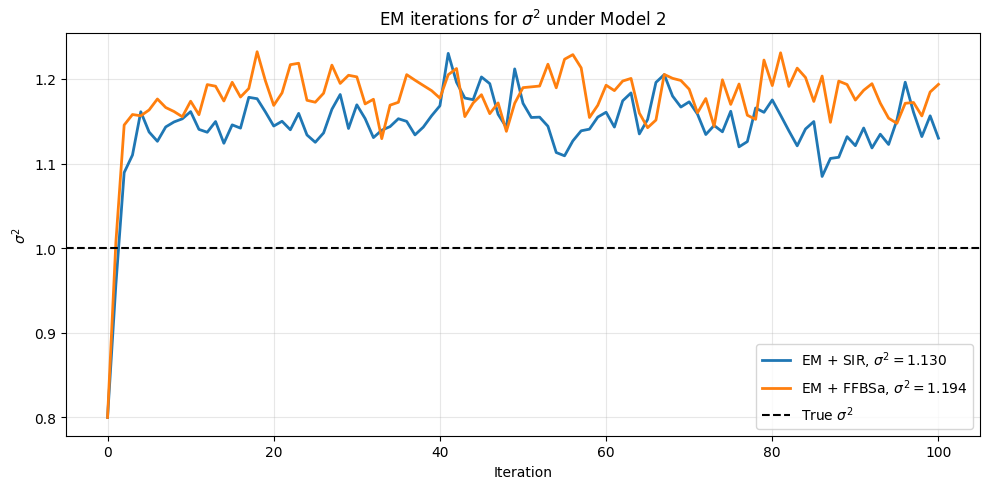

In [12]:
# ==================================================
# Particle filter for Model 2
# weighted particles stored before resampling
# ==================================================
def PF_model2_store(y, sigma, num=100, A=0.8, B=0.5):
    T = len(y)

    x_weighted = np.empty((num, T))
    weights = np.empty((num, T))
    particles = np.empty((num, T))

    loglik = 0.0

    def log_weight(x, y_obs):
        var = sigma**2 * np.exp(x)
        var = np.maximum(var, 1e-300)
        return -0.5 * (np.log(2 * np.pi * var) + (y_obs - x)**2 / var)

    # t = 0
    x_weighted[:, 0] = rng.normal(0.0, 1.0, size=num)
    logw = log_weight(x_weighted[:, 0], y[0])
    logw = np.where(np.isfinite(logw), logw, -1e300)

    m = np.max(logw)
    w = np.exp(logw - m)
    mean_w = np.mean(w)

    if (not np.isfinite(mean_w)) or (mean_w <= 0):
        weights[:, 0] = np.ones(num) / num
        loglik += -1e300
    else:
        loglik += m + np.log(mean_w)
        weights[:, 0] = w / np.sum(w)

    idx = rng.choice(num, size=num, replace=True, p=weights[:, 0])
    particles[:, 0] = x_weighted[idx, 0]

    # t = 1, ..., T-1
    for t in range(1, T):
        x_weighted[:, t] = A * particles[:, t - 1] + rng.normal(0.0, B, size=num)

        logw = log_weight(x_weighted[:, t], y[t])
        logw = np.where(np.isfinite(logw), logw, -1e300)

        m = np.max(logw)
        w = np.exp(logw - m)
        mean_w = np.mean(w)

        if (not np.isfinite(mean_w)) or (mean_w <= 0):
            weights[:, t] = np.ones(num) / num
            loglik += -1e300
        else:
            loglik += m + np.log(mean_w)
            weights[:, t] = w / np.sum(w)

        idx = rng.choice(num, size=num, replace=True, p=weights[:, t])
        particles[:, t] = x_weighted[idx, t]

    return loglik, particles, x_weighted, weights


# ==================================================
# FFBSa for Model 2
# ==================================================
def ffbsa_model2(y, sigma, num=100, A=0.8, B=0.5):
    loglik, particles, x_weighted, weights = PF_model2_store(y, sigma, num=num, A=A, B=B)

    T = len(y)
    x_smoothed = np.empty(T)

    idx = rng.choice(num, p=weights[:, -1])
    x_smoothed[-1] = x_weighted[idx, -1]

    for t in range(T - 2, -1, -1):
        mean = A * x_weighted[:, t]
        log_trans = -0.5 * (
            np.log(2 * np.pi * B**2) + (x_smoothed[t + 1] - mean)**2 / (B**2)
        )

        log_prob = np.log(weights[:, t] + 1e-300) + log_trans
        m = np.max(log_prob)
        prob = np.exp(log_prob - m)
        prob /= np.sum(prob)

        idx = rng.choice(num, p=prob)
        x_smoothed[t] = x_weighted[idx, t]

    return x_smoothed, loglik


# ==================================================
# EM update using SIR filtering approximation
# M-step:
# sigma2_new = E[S | y] / T
# where S = sum_t (y_t - x_t)^2 exp(-x_t)
# ==================================================
def em_update_sigma2_sir(y, sigma2_old, num=100, A=0.8, B=0.5):
    sigma_old = np.sqrt(sigma2_old)
    loglik, particles, x_weighted, weights = PF_model2_store(
        y, sigma_old, num=num, A=A, B=B
    )

    T = len(y)
    E_S = 0.0

    for t in range(T):
        term = (y[t] - x_weighted[:, t])**2 * np.exp(-x_weighted[:, t])
        E_S += np.sum(weights[:, t] * term)

    sigma2_new = E_S / T
    return sigma2_new, loglik


# ==================================================
# EM update using FFBSa smoothing approximation
# Approximate E[S | y] by averaging over M smoothed paths
# ==================================================
def em_update_sigma2_ffbsa(y, sigma2_old, num=100, M=30, A=0.8, B=0.5):
    sigma_old = np.sqrt(sigma2_old)
    T = len(y)

    S_vals = np.empty(M)
    loglik_vals = np.empty(M)

    for m in range(M):
        x_path, loglik = ffbsa_model2(y, sigma_old, num=num, A=A, B=B)
        S_vals[m] = np.sum((y - x_path)**2 * np.exp(-x_path))
        loglik_vals[m] = loglik

    E_S_hat = np.mean(S_vals)
    sigma2_new = E_S_hat / T

    return sigma2_new, np.mean(loglik_vals)


# ==================================================
# Run EM iterations for SIR
# ==================================================
def run_em_sir(y, sigma2_init=0.8, n_iter=100, num=100, A=0.8, B=0.5):
    sigma2_path = np.empty(n_iter + 1)
    loglik_path = np.empty(n_iter)
    sigma2_path[0] = sigma2_init

    for k in range(n_iter):
        sigma2_new, loglik = em_update_sigma2_sir(
            y, sigma2_path[k], num=num, A=A, B=B
        )
        sigma2_path[k + 1] = sigma2_new
        loglik_path[k] = loglik

    return sigma2_path, loglik_path


# ==================================================
# Run EM iterations for FFBSa
# ==================================================
def run_em_ffbsa(y, sigma2_init=0.8, n_iter=100, num=100, M=30, A=0.8, B=0.5):
    sigma2_path = np.empty(n_iter + 1)
    loglik_path = np.empty(n_iter)
    sigma2_path[0] = sigma2_init

    for k in range(n_iter):
        sigma2_new, loglik = em_update_sigma2_ffbsa(
            y, sigma2_path[k], num=num, M=M, A=A, B=B
        )
        sigma2_path[k + 1] = sigma2_new
        loglik_path[k] = loglik

    return sigma2_path, loglik_path


# ==================================================
# Example
# ==================================================
sir_em_path, sir_loglik = run_em_sir(
    obs_model2, sigma2_init=0.8, n_iter=100, num=100, A=0.8, B=0.5
)

ffbsa_em_path, ffbsa_loglik = run_em_ffbsa(
    obs_model2, sigma2_init=0.8, n_iter=100, num=100, M=30, A=0.8, B=0.5
)

plt.figure(figsize=(10, 5))
plt.plot(sir_em_path, label=f'EM + SIR, $\\sigma^2 = {sir_em_path[-1]:.3f}$', lw=2)
plt.plot(ffbsa_em_path, label=f'EM + FFBSa, $\\sigma^2 = {ffbsa_em_path[-1]:.3f}$', lw=2)
plt.axhline(1.0, color='black', linestyle='--', label='True $\\sigma^2$')
plt.xlabel('Iteration')
plt.ylabel('$\\sigma^2$')
plt.title('EM iterations for $\\sigma^2$ under Model 2')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()